# Predicting molecular-replacement success honestly: audit, leakage, nested cross-validation

**Module 03.2 · my implementation**, Seid Adem

The course tutorial trains eight classifiers to predict whether **molecular replacement (MR)** will succeed for an
X-ray crystallography experiment. This notebook re-does that work with the safeguards a real project needs, and
finds that **the tutorial's setup overestimates performance**, for a reason that is easy to miss.

> **New to the domain?** Read the [background on crystallography and MR](../LESSONS.md#background--the-tutorial-dataset-in-plain-language)
> first. In one paragraph: to see a protein's 3-D structure, scientists grow a crystal and record how it scatters
> X-rays. Turning that pattern into a structure needs extra information (the "phases"), and MR borrows it from a
> similar, already-known structure, the **search model**. Sometimes this works and sometimes it doesn't. Each row
> of the dataset is one attempt, described by numbers about **data quality** (how sharp, complete and clean the
> measurements are) and about the **search model**, with the outcome `MR_success` (1 = worked, 0 = failed).
>
> **New to ML evaluation?** The relevant lessons are [data leakage](../LESSONS.md#lesson-2--data-leakage-the-most-common-way-to-fool-yourself),
> [splitting](../LESSONS.md#lesson-3--splitting-train-validation-test-and-stratification) and
> [hyperparameter tuning](../LESSONS.md#lesson-5--hyperparameters-and-how-to-tune-them).

**What this notebook does**

1. **Audits the data** before modelling and fixes four problems.
2. **Decides which columns are allowed as inputs**, using domain knowledge about *when* each number becomes known.
3. **Finds hidden duplicates**: the same crystal appears in several rows, and that inflates random-split scores.
4. **Compares the eight course classifiers with nested, grouped cross-validation** inside leakage-free pipelines.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    RandomForestClassifier,
)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from dsls.mr import COURSE_FEATURES, GROUP, LABEL, POST_MR_FEATURES, load_mr_data

DATA = Path("../course_materials/DataScience_EBI/tutorials/data.csv")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings(
    "ignore", category=UserWarning
)  # quiet AdaBoost/SVC deprecation notes; errors still raise
SEED = 0

## 1 · Audit the data before modelling

> **In plain language.** Before any model, check that every column means what you think it means. Computers happily
> fit models to text that should be numbers, codes that should be categories, and zeros that really mean "missing".

In [2]:
raw = pd.read_csv(DATA)  # naive read, no options
print(f"{raw.shape[0]} rows × {raw.shape[1]} columns; success rate {raw[LABEL].mean():.0%}")
print(
    "columns read as text although they hold numbers:",
    [c for c in raw.select_dtypes("object") if c not in ("mr_sg", "model_pdb")],
)
print("example LLG values:", raw["LLG"].head(3).tolist())

663 rows × 38 columns; success rate 44%
columns read as text although they hold numbers: ['LLG', 'eLLG', 'totalobservations', 'totalunique']
example LLG values: ['55.00', '2,449.00', '2,449.00']


**Problem 1: numbers stored as text.** Values like `"2,449.00"` use a thousands separator, so a naive read
gives text. (The course notebooks handle this with `thousands=","`.)

In [3]:
codes = raw.loc[raw["mr_sg_no"] > 230, ["mr_sg", "mr_sg_no"]].value_counts()
print("space-group numbers above 230 (there are only 230 space groups):")
print(codes.to_string())
print(
    f"\nmodel_res == 0 Å: {(raw['model_res'] == 0).sum()} rows; model_res > 10 Å: {(raw['model_res'] > 10).sum()} row"
)

space-group numbers above 230 (there are only 230 space groups):
mr_sg   mr_sg_no
P22121  1018        16
P21221  2018         6
P2122   1017         1

model_res == 0 Å: 20 rows; model_res > 10 Å: 1 row


**Problem 2: codes treated as quantities.** A crystal's **space group** describes its symmetry; there are 230 of them.
The values 1017, 1018 and 2018 are CCP4 software codes for alternative *axis settings* of space groups 17 and 18
(the names `P22121`, `P21221` confirm this). As numbers they would be "100× bigger" than the others and dominate any
scaled model. I map them back to 17/18. Even then the space group is really a *category*, not a quantity; trees cope
with that, linear models less well.

**Problem 3: zeros that mean "missing".** A search model with a resolution of 0 Å is impossible, so these 20 zeros are
missing values. Filling them with 0 (as the tutorial's `fillna(0)` would for real gaps) tells the model "this search
model is infinitely sharp". I mark them missing and **impute the median inside the pipeline** (so the median is
computed from training data only).

**Problem 4: near-duplicate columns.** Some pairs are almost the same measurement:

In [4]:
df = load_mr_data(DATA)  # applies the fixes above; tested in tests/test_mr.py
corr = df[COURSE_FEATURES].corr().abs()
pairs = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(corr)
    for b in corr.columns[i + 1 :]
    if corr.loc[a, b] > 0.95
]
print("feature pairs with |r| > 0.95:", pairs)

feature pairs with |r| > 0.95: [('RmergeI', 'RmeasI', np.float64(0.989)), ('multiplicity', 'anomalousmulti', np.float64(0.999)), ('RmeasdiffI', 'RmergediffI', np.float64(0.984))]


Redundant pairs don't break tree models, but they split "importance" between twins and make linear coefficients
unstable. I keep them here, to stay comparable with the course, and let feature selection in the pipeline handle them.

## 2 · Which columns may the model use?

> **In plain language.** A prediction is only useful if it can be made **before** the thing you're predicting
> happens. Ask of every column: *"would I know this value at the moment I need the prediction?"* Here, the point is
> to predict, **before running MR**, whether it is worth trying.

| Group | Columns | Known before MR? |
|-------|---------|------------------|
| Data quality | resolution, completeness, I/σ, R-factors, multiplicity, … | ✅ measured from the diffraction data |
| Search-model descriptors | `eLLG` (expected LLG), `model_res`, `tncs` | ✅ estimated before the search |
| Search-model similarity | `seq_ident` (% identical amino acids between target and search model) | ✅ computed by sequence alignment when the model is chosen; **not used by the course** |
| **MR results** | **`TFZ`, `LLG`, `PAK`, `VRMS`** | ❌ **produced by the MR run itself** |

How strongly does each single column "predict" the outcome on its own? (ROC-AUC: 0.5 = useless, 1 = perfect.)

In [5]:
single = pd.Series(
    {c: roc_auc_score(df[LABEL], df[c]) for c in POST_MR_FEATURES + ["eLLG", "IoverSigma", "highreslimit"]}
)
single = single.where(single >= 0.5, 1 - single).sort_values(ascending=False)  # direction-free
print(single.round(3).to_string())
print(
    f"\nLLG of successes: min {df.loc[df[LABEL] == 1, 'LLG'].min():.0f};  "
    f"LLG of failures: max {df.loc[df[LABEL] == 0, 'LLG'].max():.0f}"
)

LLG             0.997
TFZ             0.973
VRMS            0.869
PAK             0.756
eLLG            0.710
highreslimit    0.585
IoverSigma      0.557

LLG of successes: min 62;  LLG of failures: max 99


**LLG alone separates success from failure almost perfectly** (AUC ≈ 1.0): every success has an LLG of at least 62.
That is no surprise, because crystallographers *judge* MR success largely from LLG and TFZ. A model given these columns
isn't predicting; it's reading the answer. The course's training notebooks correctly leave them out, and so do I.
Section 4 shows the scores they would produce.

## 3 · Hidden duplicates: the same crystal in several rows

> **In plain language.** Cross-validation assumes the test rows are *new*. If the same crystal appears in both the
> training and the test part, a model can score well simply by **recognising** it, and that tells you nothing about
> crystals it has never seen.

In [6]:
per_target = df.groupby(GROUP)[LABEL].agg(["size", "min", "max"])
multi = per_target[per_target["size"] > 1]
print(
    f"{len(df)} rows come from {df[GROUP].nunique()} crystal targets; {len(multi)} targets have 2–{multi['size'].max()} rows"
)
print(f"targets whose rows disagree on the outcome: {(multi['min'] != multi['max']).sum()}")

X_scaled = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[COURSE_FEATURES]))
nearest = NearestNeighbors(n_neighbors=2).fit(X_scaled).kneighbors(X_scaled, return_distance=False)[:, 1]
in_multi = df[GROUP].isin(multi.index).to_numpy()
same = (df[GROUP].to_numpy()[nearest] == df[GROUP].to_numpy())[in_multi].mean()
print(f"rows from multi-row targets whose most similar other row is the same target: {same:.0%}")

663 rows come from 359 crystal targets; 164 targets have 2–5 rows
targets whose rows disagree on the outcome: 0
rows from multi-row targets whose most similar other row is the same target: 79%


**Every target with several rows has the same outcome in all of them**, and most of those rows' nearest neighbour is
another row of the *same* crystal. A random split will put sister rows on both sides, so a flexible model can just
look up "the crystal like this one succeeded".

**The fix: split by target.** `StratifiedGroupKFold` keeps all rows of a crystal in the same fold, while balancing
successes across folds.

## 4 · How much do the two leaks inflate the scores?

The same two models (a random forest and a logistic regression in leakage-safe pipelines), three feature sets, two
ways of splitting. Each cell is the mean ROC-AUC over 3 × 5-fold cross-validation.

In [7]:
def pipeline(model, select_k="all"):
    # Impute, scale and select are all *learned* steps, so they live inside the pipeline and are refitted on the
    # training part of every split: no information from the test part can reach them.
    return Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("select", SelectKBest(f_classif, k=select_k)),
            ("model", model),
        ]
    )


y, groups = df[LABEL].to_numpy(), df[GROUP].to_numpy()
feature_sets = {
    "course features (pre-MR)": COURSE_FEATURES,
    "+ sequence identity (pre-MR)": COURSE_FEATURES + ["seq_ident"],
    "+ MR results (TFZ, LLG, PAK, VRMS)": COURSE_FEATURES + POST_MR_FEATURES,
}
splitters = {"random split": StratifiedKFold, "grouped by crystal": StratifiedGroupKFold}
simple_models = {
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=4),
    "logistic regression": LogisticRegression(max_iter=5000),
}
rows = []
for fs_name, cols in feature_sets.items():
    for split_name, splitter in splitters.items():
        for model_name, model in simple_models.items():
            scores = np.concatenate(
                [
                    cross_val_score(
                        pipeline(model),
                        df[cols],
                        y,
                        groups=groups,
                        scoring="roc_auc",
                        cv=splitter(n_splits=5, shuffle=True, random_state=rep),
                    )
                    for rep in range(3)
                ]
            )
            rows.append(
                {
                    "features": fs_name,
                    "split": split_name,
                    "model": model_name,
                    "ROC-AUC": scores.mean(),
                    "SD": scores.std(),
                }
            )
leak = pd.DataFrame(rows)
leak.pivot_table(index=["features", "model"], columns="split", values="ROC-AUC").round(3)

split                                                   grouped by crystal  \
features                           model                                     
+ MR results (TFZ, LLG, PAK, VRMS) logistic regression               0.989   
                                   random forest                     0.999   
+ sequence identity (pre-MR)       logistic regression               0.855   
                                   random forest                     0.885   
course features (pre-MR)           logistic regression               0.737   
                                   random forest                     0.742   

split                                                   random split  
features                           model                              
+ MR results (TFZ, LLG, PAK, VRMS) logistic regression         0.996  
                                   random forest               1.000  
+ sequence identity (pre-MR)       logistic regression         0.876  
                                   random forest               0.975  
course features (pre-MR)           logistic regression         0.770  
                                   random forest               0.927

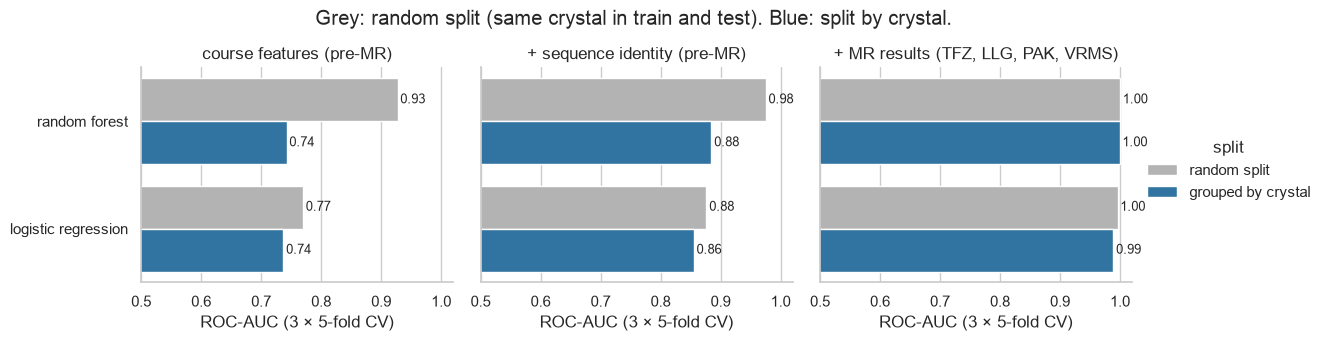

In [8]:
g = sns.catplot(
    data=leak,
    x="ROC-AUC",
    y="model",
    hue="split",
    col="features",
    kind="bar",
    height=3.2,
    aspect=1.25,
    palette=["0.7", "tab:blue"],
    errorbar=None,
)
for ax in g.axes.flat:
    ax.set_xlim(0.5, 1.02)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", padding=2, fontsize=9)
g.set_titles("{col_name}")
g.set_axis_labels("ROC-AUC (3 × 5-fold CV)", "")
g.figure.suptitle("Grey: random split (same crystal in train and test). Blue: split by crystal.", y=1.06)
g.savefig(FIGURES / "01_leakage_effects.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the three panels**

* **Left (the course's features): the random forest falls from 0.93 to 0.74 when crystals can't appear on both
  sides.** Logistic regression barely moves (0.77 → 0.74). A straight-line model can't memorise individual crystals;
  a forest of deep trees can. So **most of the random forest's apparent advantage was recognition of crystals it had
  already seen**. On genuinely new crystals the two models are equal.
* **Right (MR results as inputs): about 1.00 whatever the split.** It is the target leakage from section 2: the label
  is effectively a threshold on LLG.
* **Middle (adding sequence identity): 0.86–0.88 on unseen crystals,** a large, *legitimate* gain. How similar the
  search model is to the target is known before MR and is the classic predictor of MR success. Domain knowledge beat
  model choice: one well-chosen feature added more than any algorithm below.

> **In plain language.** The same algorithm, on the same data, scored 0.93 or 0.74 depending only on *how the
> data was split*. The 0.74 is the honest answer to "how well will this work on the next crystal?". When rows come
> in related groups (several samples per patient, several images per slide, several sweeps per crystal), **split by
> group**.

The rest of this notebook uses the course's 27 features and grouped splits, to stay comparable with the tutorial.

## 5 · Nested cross-validation over the course's eight classifiers

> **In plain language.** Each model has settings (**hyperparameters**) that must be tuned. If you tune them on the
> same folds you report, the score is optimistic: you picked the settings that happened to suit those folds.
> **Nested cross-validation** uses two loops:
> * the **inner loop** (3 folds, inside the training part only) tries 15 random settings and picks the best;
> * the **outer loop** (5 folds × 3 repeats) scores that *whole tuning procedure* on crystals it has never seen.
>
> Both loops split **by crystal**. The pipeline (impute → scale → select the *k* best features → model) is refitted
> at every step, and *k* itself is tuned.

The eight classifiers are those of the course tutorial, plus a **no-skill baseline** and **logistic regression** as a
simple reference point.

In [9]:
K = {"select__k": [8, 12, 18, 27]}
search_spaces = {
    "Baseline (prior)": (DummyClassifier(strategy="prior"), None),
    "Logistic regression": (LogisticRegression(max_iter=5000), {**K, "model__C": loguniform(1e-3, 1e2)}),
    "Linear SVM": (SVC(kernel="linear"), {**K, "model__C": loguniform(1e-3, 1e1)}),
    "RBF SVM": (
        SVC(kernel="rbf"),
        {**K, "model__C": loguniform(1e-2, 1e3), "model__gamma": loguniform(1e-4, 1)},
    ),
    "Decision tree": (
        DecisionTreeClassifier(random_state=SEED),
        {**K, "model__max_depth": randint(2, 12), "model__min_samples_leaf": randint(1, 30)},
    ),
    "Bagging": (
        BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=SEED),
        {**K, "model__max_samples": uniform(0.3, 0.7), "model__max_features": uniform(0.3, 0.7)},
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=SEED),
        {**K, "model__n_estimators": randint(50, 400), "model__learning_rate": loguniform(1e-2, 1)},
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED),
        {
            **K,
            "model__max_depth": [3, 5, 8, None],
            "model__min_samples_leaf": randint(1, 20),
            "model__max_features": uniform(0.1, 0.6),
        },
    ),
    "Extra trees": (
        ExtraTreesClassifier(n_estimators=300, random_state=SEED),
        {
            **K,
            "model__max_depth": [3, 5, 8, None],
            "model__min_samples_leaf": randint(1, 20),
            "model__max_features": uniform(0.1, 0.6),
        },
    ),
    "KNN": (
        KNeighborsClassifier(),
        {**K, "model__n_neighbors": randint(3, 60), "model__weights": ["uniform", "distance"]},
    ),
}

X = df[COURSE_FEATURES]
records, chosen = [], []
for rep in range(3):
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=rep)
    for fold, (train, test) in enumerate(outer.split(X, y, groups)):
        for name, (model, space) in search_spaces.items():
            est = pipeline(model)
            if space is not None:
                inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=rep)
                est = RandomizedSearchCV(
                    est, space, n_iter=15, cv=inner, scoring="roc_auc", random_state=rep, n_jobs=4
                )
                est.fit(X.iloc[train], y[train], groups=groups[train])
                chosen.append({"model": name, "repeat": rep, "fold": fold, **est.best_params_})
            else:
                est.fit(X.iloc[train], y[train])
            score = (
                est.decision_function(X.iloc[test])
                if hasattr(est, "decision_function")
                else est.predict_proba(X.iloc[test])[:, 1]
            )
            pred = est.predict(X.iloc[test])
            records.append(
                {
                    "model": name,
                    "repeat": rep,
                    "fold": fold,
                    "ROC-AUC": roc_auc_score(y[test], score),
                    "balanced accuracy": balanced_accuracy_score(y[test], pred),
                    "recall (successes found)": recall_score(y[test], pred),
                }
            )
nested = pd.DataFrame(records)
summary = nested.groupby("model").agg(["mean", "std"]).drop(columns=["repeat", "fold"]).round(3)
summary = summary.sort_values(("ROC-AUC", "mean"), ascending=False)
summary

ROC-AUC        balanced accuracy         \
                       mean    std              mean    std   
model                                                         
Logistic regression   0.757  0.057             0.705  0.048   
Random forest         0.756  0.064             0.732  0.046   
Linear SVM            0.755  0.064             0.689  0.055   
AdaBoost              0.751  0.048             0.715  0.054   
RBF SVM               0.747  0.064             0.655  0.095   
Bagging               0.742  0.055             0.712  0.047   
Extra trees           0.734  0.056             0.701  0.044   
Decision tree         0.732  0.060             0.705  0.056   
KNN                   0.710  0.043             0.680  0.045   
Baseline (prior)      0.500  0.000             0.500  0.000   

                    recall (successes found)         
                                        mean    std  
model                                                
Logistic regression                    0.556  0.109  
Random forest                          0.604  0.091  
Linear SVM                             0.499  0.122  
AdaBoost                               0.515  0.125  
RBF SVM                                0.392  0.234  
Bagging                                0.604  0.095  
Extra trees                            0.518  0.103  
Decision tree                          0.599  0.127  
KNN                                    0.508  0.090  
Baseline (prior)                       0.000  0.000

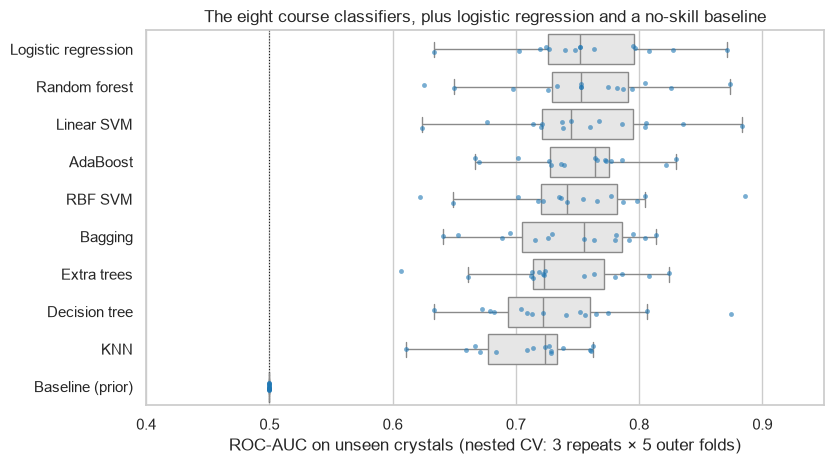

In [10]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.boxplot(data=nested, y="model", x="ROC-AUC", order=order, color="0.9", showfliers=False, ax=ax)
sns.stripplot(data=nested, y="model", x="ROC-AUC", order=order, size=3.5, alpha=0.6, color="tab:blue", ax=ax)
ax.axvline(0.5, color="k", lw=0.8, ls=":")
ax.set(
    xlabel="ROC-AUC on unseen crystals (nested CV: 3 repeats × 5 outer folds)", ylabel="", xlim=(0.4, 0.95)
)
ax.set_title("The eight course classifiers, plus logistic regression and a no-skill baseline")
fig.tight_layout()
fig.savefig(FIGURES / "02_nested_cv.png", dpi=150)
plt.show()

**Reading the result**

* **All real models beat the baseline (0.50), and seven of them are statistically tied** (mean ROC-AUC 0.73–0.76,
  fold-to-fold SD about 0.05–0.06). The ranking within that band is noise.
* **Logistic regression is joint best (0.757)**, level with the random forest (0.756). Given a tie, the simpler,
  faster and more interpretable model is the professional choice.
* **KNN is last (0.71).** Distance-based methods suffer when many features are weakly informative.
* **Balanced accuracy and recall tell a different story from AUC.** The RBF SVM ranks well by AUC (it *orders*
  crystals reasonably) but finds only 39 % of successes at its default threshold, with a very large spread (SD 0.23).
  The random forest and bagging find about 60 %. Which matters depends on the use: ranking crystals to try first, or
  making yes/no calls. Notebook 02 looks at thresholds.

**How stable are the "best" settings?** If tuning picks very different settings in each outer fold, the
"optimal hyperparameters" reported by a single search are partly noise:

In [11]:
chosen = pd.DataFrame(chosen)
rf = chosen[chosen["model"] == "Random forest"].dropna(axis=1, how="all")
print("random forest, chosen settings across the 15 outer folds:")
print(
    rf.drop(columns=["model", "repeat", "fold"])
    .describe(include="all")
    .loc[["count", "mean", "min", "max"]]
    .round(2)
    .to_string()
)
print("\nnumber of selected features (k) chosen per model:")
print(chosen.groupby("model")["select__k"].value_counts().unstack(fill_value=0).to_string())

random forest, chosen settings across the 15 outer folds:
       select__k  model__max_depth  model__min_samples_leaf  model__max_features
count       15.0             15.00                    15.00                15.00
mean        13.4              3.53                    12.33                 0.45
min          8.0              3.00                     1.00                 0.28
max         27.0              5.00                    19.00                 0.70

number of selected features (k) chosen per model:
select__k            8   12  18  27
model                              
AdaBoost             10   2   2   1
Bagging               7   2   2   4
Decision tree         8   0   2   5
Extra trees           7   3   1   4
KNN                  10   3   2   0
Linear SVM           11   4   0   0
Logistic regression  11   4   0   0
RBF SVM               8   4   3   0
Random forest         9   1   2   3


* **The forest always chose shallow trees** (max depth 3–5, never unlimited) and large leaves (12 samples on
  average). On unseen crystals, deep trees that can memorise individual crystals don't pay off, which matches
  section 4.
* **Most models chose the smallest feature set offered (k = 8),** so a handful of the 27 columns carries most of
  the signal.
* **The chosen values vary a lot between folds** (e.g. `min_samples_leaf` from 1 to 19). That is why a single
  "best hyperparameters" list, like the one hard-coded in the tutorial's random-forest notebook, shouldn't be read as
  a precise finding.

## Conclusions

1. **Audit first.** Four data problems (numbers stored as text, space-group codes, zeros meaning "missing", duplicated
   measurements) were fixed before modelling, in tested code.
2. **Ask "would I know this value in time?"** The MR results (TFZ, LLG, …) make the task trivial (AUC ≈ 1.0) because
   the label is judged from them. They must be excluded, as the course does.
3. **Split by crystal.** 359 crystals provide the 663 rows, and repeated crystals always share their outcome. A random
   split inflated the random forest from **0.74 to 0.93**. This is the most important finding here, and the
   tutorial's random split is affected by it.
4. **With honest evaluation, model choice hardly matters:** seven of the eight course classifiers and logistic
   regression score 0.73–0.76 on unseen crystals. I would choose **logistic regression**: joint best, simplest,
   interpretable.
5. **Domain knowledge matters more than the algorithm:** adding *sequence identity*, which is known before MR,
   raises grouped AUC to about 0.86–0.88, more than any model change.

**Next:** [notebook 02](02_mr_imbalance_and_learning_curves.ipynb) studies class imbalance and thresholds, and uses
learning curves to ask whether more data would help.

---
*Data: `data.csv` from the course's [DataScience_EBI tutorial](../course_materials/DataScience_EBI/) (MIT licence,
see its `LICENSE`), built from structures solved at the JCSG and SGC structural-genomics centres (slide 77 of the
course slides). The cleaning steps are
in [`src/dsls/mr.py`](../../../src/dsls/mr.py) and tested in [`tests/test_mr.py`](../../../tests/test_mr.py). Runs
in about 5 minutes on a laptop.*